# Week 6: Language Models
AI for Good - Minor ADSAI

[Open this notebook in Google Colab](https://colab.research.google.com/github/BTuyn/AI4G/blob/main/Week%206/Week6_Workshop_Student.ipynb) - nothing to install, everything
runs in your browser. If you opened it in Colab already: great.

Today you meet the three ideas behind every modern language model, one at a
time, each one fixing a problem of the one before:

| Step | Model | What it adds |
|------|-------|--------------|
| 1 | **Word embeddings** | words become numbers that carry meaning |
| 2 | **RNN**, then **LSTM** | reading in order, and remembering what you read |
| 3 | **Transformer** | looking at every word at once, so context decides the meaning |

You do **not** build or train any of these today. You use ready-made models
and look at what they do well, where they break, and who gets hurt when they
break. The spine of the week is the same as in Weeks 4 and 5:
**text -> numbers -> model -> prediction**.

Today runs in **three learning waves**, each starting with a short
mini-lecture. A wave starts at every horizontal line in this notebook,
marked like this:

**LEARNING WAVE 1 · SLIDES 4-8**

- Wave 1 - section 1: words as numbers (embeddings)
- Wave 2 - section 2: order and memory (RNN and LSTM)
- Wave 3 - section 3: context and attention (transformers)
- Then section 4: the big individual assignment, and section 5: wrap-up

Do not run ahead into the next wave - wait for the mini-lecture.

### 0. Setup - run these two cells once

Nothing to write here. Run each cell with Shift + Enter and wait until it
finishes (the first one downloads a 66 MB file, a few seconds). If a cell
prints a long warning about a missing token or about "unauthenticated
requests", ignore it.

In [15]:
%pip install numpy matplotlib pandas torch transformers

  Using cached numpy-2.5.4-cp312-cp312-win_amd64.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached pyyaml-6.0.3-cp312-cp312-win_amd64.whl.metadata (2.4 kB)
  Using cached regex-2026.9.29-cp312-cp312-win_amd64.whl.metadata (41 kB)
  Using cached tokenizers-0.23.3-cp310-abi3-win_amd64.whl.metadata (10 kB)
  Using cached typer-0.27.3-py3-none-any.whl.metadata (16 kB)
  Using cached safetensors-0.8.0-cp310-abi3-win_amd64.whl.metadata (4.2 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
  Using cached markupsafe-3.0.4-cp312-cp312-win_amd64.whl.metadata (2.8 kB)
  Using cached shellingham-1.5.4-py2.py3-none-any.whl.m

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress t

In [16]:
# Run, do not read: downloads the pre-trained word embeddings (GloVe, trained by Stanford)
import urllib.request, gzip
import numpy as np
import matplotlib.pyplot as plt

url = "https://github.com/RaRe-Technologies/gensim-data/releases/download/glove-wiki-gigaword-50/glove-wiki-gigaword-50.gz"
urllib.request.urlretrieve(url, "glove50.gz")

words = []
vectors = []
with gzip.open("glove50.gz", "rt", encoding="utf-8") as f:
    f.readline()                       # first line is just file info
    for i, line in enumerate(f):
        if i >= 50000:                 # keep the 50,000 most common words
            break
        parts = line.rstrip().split(" ")
        words.append(parts[0])
        vectors.append(np.array(parts[1:], dtype="float32"))

V = np.vstack(vectors)
V = V / np.linalg.norm(V, axis=1, keepdims=True)   # length 1, so a dot product = similarity
index = {}
for i, w in enumerate(words):
    index[w] = i
print("Loaded", len(words), "words, each one a list of", V.shape[1], "numbers")

Matplotlib is building the font cache; this may take a moment.


Loaded 50000 words, each one a list of 50 numbers


In [18]:
# Run, do not read: small helper functions that we use all day
def vector(word):
    return V[index[word]]

def similarity(a, b):
    # 1.0 = used in exactly the same way, 0 = nothing in common
    return round(float(vector(a) @ vector(b)), 2)

def neighbours(word, n=8):
    scores = V @ vector(word)
    best = np.argsort(-scores)[1:n + 1]
    return [(words[i], round(float(scores[i]), 2)) for i in best]

def analogy(a, b, c, n=5):
    # "a is to b as c is to ?"   (for example: man is to king as woman is to ?)
    target = vector(b) - vector(a) + vector(c)
    scores = V @ target
    result = []
    for i in np.argsort(-scores):
        if words[i] not in (a, b, c):
            result.append(words[i])
        if len(result) == n:
            break
    return result

def plot_words(word_list):
    # squash the 50 numbers per word into 2, so we can draw a map
    X = np.array([vector(w) for w in word_list])
    X = X - X.mean(axis=0)
    u, s, vt = np.linalg.svd(X, full_matrices=False)
    xy = X @ vt[:2].T
    plt.figure(figsize=(8, 6))
    plt.scatter(xy[:, 0], xy[:, 1])
    for k, w in enumerate(word_list):
        plt.text(xy[k, 0] + 0.02, xy[k, 1] + 0.02, w, fontsize=11)
    plt.title("Words on a map (50 numbers squashed into 2)")
    plt.axis("off")
    plt.show()

---

**LEARNING WAVE 1 · SLIDES 4-8**

## 1. Words as numbers

Sections 1.1 to 1.7. From counting words to giving every word a position on a map of meaning.

### 1.1 What is an embedding?

In slide 5 a sentence became a row of word counts. A count tells you *which*
words appear, but not what they *mean*: to a count, `dog` and `cat` are as
unrelated as `dog` and `car`.

An **embedding** fixes that. Every word gets a list of numbers, and words
that are used in similar ways get similar numbers. The file you just loaded
was trained by Stanford on billions of words. It is **pre-trained**: you do
not train anything today.

Run the cell below. It shows the list of numbers for the word `clinic`.

In [19]:
print(vector("clinic")[:10])
print("This word is a list of", len(vector("clinic")), "numbers. We only printed the first 10.")

[ 0.21052876  0.05483797 -0.15234819 -0.07561343 -0.1071714   0.04723899
 -0.174664    0.03915308  0.24461457 -0.03759914]
This word is a list of 50 numbers. We only printed the first 10.


Your answer:An embedding turns a word into a list of numbers. Words with similar meanings or uses have similar numbers. The word clinic has 50 numbers.


In [22]:
print(vector("clinic")[:10])

[ 0.21052876  0.05483797 -0.15234819 -0.07561343 -0.1071714   0.04723899
 -0.174664    0.03915308  0.24461457 -0.03759914]


### 1.2 How close are two words?

`similarity(a, b)` compares the two lists of numbers. It gives **1.0** when
two words are used in exactly the same way and values near **0** when they
have nothing in common.

**Predict first.** Which of these five pairs will be the most similar, and
which the least?

- `dog` and `cat`
- `dog` and `car`
- `doctor` and `nurse`
- `clinic` and `hospital`
- `king` and `banana`

Your prediction: I think clinic and hospital will be the most similar because they are both healthcare places. I think king and banana will be the least similar.


In [23]:
pairs = [("dog", "cat"), ("dog", "car"), ("doctor", "nurse"), ("clinic", "hospital"), ("king", "banana")]
for pair in pairs:
    print(pair[0], "-", pair[1], ":", similarity(pair[0], pair[1]))

dog - cat : 0.92
dog - car : 0.46
doctor - nurse : 0.8
clinic - hospital : 0.86
king - banana : 0.22


Your answer:I think clinic and hospital will be the most similar because they are both healthcare places. I think king and banana will be the least similar.


### 1.3 The neighbours of a word

`neighbours("clinic")` lists the words closest to `clinic`. Run it, then try
**three words of your own** (lowercase, and a common word, otherwise it may
not be in the list).

In [24]:
print(neighbours("clinic"))
print(neighbours("hockey"))
print(neighbours("student"))
print(neighbours("music"))

[('hospital', 0.86), ('clinics', 0.82), ('psychiatric', 0.8), ('medical', 0.79), ('nursing', 0.78), ('outpatient', 0.73), ('hospice', 0.73), ('hospitals', 0.72)]
[('basketball', 0.86), ('football', 0.86), ('soccer', 0.81), ('league', 0.8), ('leagues', 0.8), ('baseball', 0.79), ('athletics', 0.78), ('nhl', 0.76)]
[('teacher', 0.9), ('students', 0.88), ('teachers', 0.86), ('graduate', 0.83), ('school', 0.82), ('teaching', 0.81), ('faculty', 0.8), ('education', 0.8)]
[('musical', 0.89), ('pop', 0.87), ('dance', 0.85), ('songs', 0.85), ('recording', 0.84), ('folk', 0.83), ('studio', 0.83), ('contemporary', 0.83)]


Your answer: The model finds words that are used in similar contexts. For example, I expect hockey to be close to other sports and student to be close to school and education.


### 1.4 Play Contexto (10 minutes, in the browser)

Open <https://contexto.me/en/> and, together with your neighbour, guess the
word of the day. After every guess the game tells you how *close* your word
is to the secret word. That is exactly the distance you computed above.

Then answer: how did you decide on your next guess?

Your answer: I used the scores of my previous guesses to choose new words. When a word was close, I tried other words with similar meanings.


### 1.5 A map of words

We cannot draw 50 numbers, so the cell below squashes them into 2 and draws a
map. Run it. Which words sit together? Which word is the odd one out?

In [ ]:
plot_words(["dog", "cat", "horse", "cow", "car", "bus", "train", "bike",
            "doctor", "nurse", "hospital", "clinic", "school", "teacher", "student",
            "king", "queen", "prince", "bread", "rice", "apple", "banana"])

Your answer: I expect animals, transport and food words to form groups. This happens because the words are used in similar contexts. The map is not perfect because 50 numbers are reduced to only two.


### 1.6 Arithmetic with meaning

Because words are numbers, you can calculate with them.
`analogy("man", "king", "woman")` answers: *man is to king as woman is to ...?*

Run the first two. Then **predict** what `analogy("man", "doctor", "woman")`
will answer, and run it.

In [25]:
print(analogy("man", "king", "woman"))
print(analogy("paris", "france", "berlin"))

['queen', 'throne', 'prince', 'daughter', 'elizabeth']
['germany', 'denmark', 'poland', 'austria', 'german']


Your prediction: I think the model will answer doctor or another medical job. But it might also show gender stereotypes from its training data.


In [ ]:
print(analogy("man", "doctor", "woman"))
print(analogy("man", "manager", "woman"))

Your answer: The model can show gender stereotypes because it learns from human-written text. For example, it might connect men more with doctors and managers, and women with nurses or assistants. This could be unfair if AI is used for hiring.


### 1.7 One word, one list of numbers

Run the cell below. `bank` has **one** list of numbers, so it has one set of
neighbours.

In [26]:
print(neighbours("bank"))

[('banks', 0.87), ('securities', 0.8), ('banking', 0.8), ('investment', 0.78), ('exchange', 0.78), ('financial', 0.77), ('credit', 0.76), ('lender', 0.75)]


Your answer: The word bank can mean a financial institution or the side of a river. This embedding gives the word only one vector, so it cannot fully understand which meaning is used in a sentence.


---

**LEARNING WAVE 2 · SLIDES 9-14**

## 2. Order and memory: RNN and LSTM

Sections 2.1 to 2.7. Word counts throw away the order of the words. A recurrent network reads the words one by one and carries a memory along. How long can it keep that memory?

### 2.1 Order matters

Bag of words and plain embeddings treat a text as a pile of words. Run the
cell below: it compares the word counts of two sentences with opposite
meanings.

In [27]:
from collections import Counter

good = "the food was good not bad at all"
bad = "the food was bad not good at all"

print(Counter(good.split()))
print(Counter(bad.split()))
print("Same counts?", Counter(good.split()) == Counter(bad.split()))

Counter({'the': 1, 'food': 1, 'was': 1, 'good': 1, 'not': 1, 'bad': 1, 'at': 1, 'all': 1})
Counter({'the': 1, 'food': 1, 'was': 1, 'bad': 1, 'not': 1, 'good': 1, 'at': 1, 'all': 1})
Same counts? True


Your answer: Both sentences have exactly the same words, but their meanings are different. This shows that word order is important and counting words is not enough to understand a sentence.


### 2.2 Telephone game (in class, 6 minutes, no laptop)

Your teacher will explain the rules. You play two rounds:

1. **The plain chain (the RNN).** A message is whispered down the line. Everyone only knows what the person before them whispered.
2. **The note-taking chain (the LSTM).** Everyone gets a small notebook and may write down one important thing from the message, keep it, and pass it on next to the whisper.

Write down what you notice: what got lost in round 1, and what did the
notebook change in round 2?

Your answer: In an RNN, information from the beginning of a long message can be forgotten. An LSTM has a better memory system that helps it keep important information for longer.


### 2.3 The memory test

A tiny game to measure memory. Every **sequence** starts with a secret
colour word (red, green, blue or yellow), followed by a number of filler
words. The model reads the whole sequence, word by word, and then has to say
**which colour the sequence started with**.

The only way to win is to remember the first word until the end.

The cell below prepares two tiny models: an **RNN** and an **LSTM**. It also
contains the function `memory_test(kind, length)`, which trains a model for
a few seconds and returns its score on new sequences (1.0 = always right,
0.25 = just guessing). Run it, then look at two examples.

In [28]:
# Run, do not read: two tiny models and a game to test their memory
import torch
import torch.nn as nn

colours = ["red", "green", "blue", "yellow"]
fillers = ["the", "cat", "sat", "on", "a", "mat", "and", "looked", "at", "dog"]

def make_data(n, length, generator):
    first = torch.randint(0, 4, (n,), generator=generator)
    filler = torch.randint(4, 14, (n, length), generator=generator)
    return torch.cat([first.unsqueeze(1), filler], dim=1), first

class TinyReader(nn.Module):
    def __init__(self, kind):
        super().__init__()
        self.embedding = nn.Embedding(14, 16)
        if kind == "rnn":
            self.reader = nn.RNN(16, 32, batch_first=True)
        else:
            self.reader = nn.LSTM(16, 32, batch_first=True)
            for name, p in self.reader.named_parameters():
                if "bias" in name:
                    p.data[32:64] = 1.0     # start with 'keep what you remember'
        self.answer = nn.Linear(32, 4)

    def forward(self, x):
        out, _ = self.reader(self.embedding(x))
        return self.answer(out[:, -1, :])    # the answer comes after the LAST word

def memory_test(kind, length, seed=1):
    torch.manual_seed(seed)
    g = torch.Generator().manual_seed(seed)
    x_train, y_train = make_data(2000, length, g)
    x_test, y_test = make_data(1000, length, g)
    net = TinyReader(kind)
    optimizer = torch.optim.Adam(net.parameters(), lr=0.01)
    loss_function = nn.CrossEntropyLoss()
    for epoch in range(30):
        order = torch.randperm(2000)
        for i in range(0, 2000, 100):
            batch = order[i:i + 100]
            optimizer.zero_grad()
            loss_function(net(x_train[batch]), y_train[batch]).backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            optimizer.step()
    with torch.no_grad():
        return round((net(x_test).argmax(1) == y_test).float().mean().item(), 2)

def show_example(length):
    g = torch.Generator().manual_seed(length)
    x, y = make_data(1, length, g)
    tokens = x[0].tolist()
    print(colours[tokens[0]], " ".join(fillers[t - 4] for t in tokens[1:]))
    print("-> the model must answer:", colours[int(y[0])])
    print()

In [ ]:
show_example(5)
show_example(15)

**Predict first.** We test sequences with 5, 10, 20 and 30 filler words
after the colour. For each length, will the model still remember the
colour? Write your guess for the RNN and for the LSTM.

Your prediction: I think the RNN will remember the colour with 5 or 10 words, but will struggle with 20 or 30 words. I expect the LSTM to perform better because it can remember information for longer.


### 2.4 Test the RNN

This trains a fresh RNN for each length (about 5 seconds each) and prints
the score.

In [29]:
lengths = [5, 10, 20, 30]
rnn_scores = []
for length in lengths:
    score = memory_test("rnn", length)
    rnn_scores.append(score)
    print("RNN, after", length, "filler words ->", score)

RNN, after 5 filler words -> 1.0
RNN, after 10 filler words -> 1.0
RNN, after 20 filler words -> 0.47
RNN, after 30 filler words -> 0.24


### 2.5 Test the LSTM

Exactly the same game, with the LSTM instead.

In [30]:
lstm_scores = []
for length in lengths:
    score = memory_test("lstm", length)
    lstm_scores.append(score)
    print("LSTM, after", length, "filler words ->", score)

LSTM, after 5 filler words -> 1.0
LSTM, after 10 filler words -> 1.0
LSTM, after 20 filler words -> 1.0
LSTM, after 30 filler words -> 1.0


### 2.6 Compare

Run the cell below to draw both results in one picture, then answer.

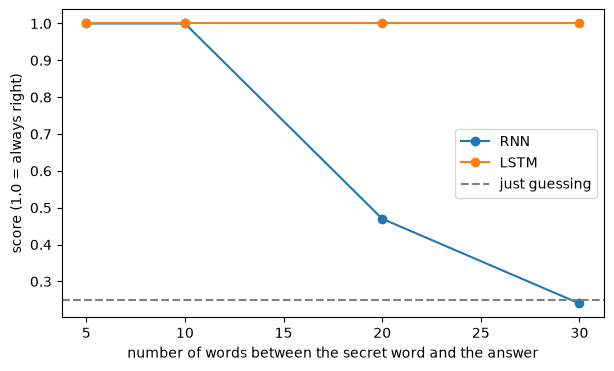

In [31]:
plt.figure(figsize=(7, 4))
plt.plot(lengths, rnn_scores, marker="o", label="RNN")
plt.plot(lengths, lstm_scores, marker="o", label="LSTM")
plt.axhline(0.25, color="grey", linestyle="--", label="just guessing")
plt.xlabel("number of words between the secret word and the answer")
plt.ylabel("score (1.0 = always right)")
plt.legend()
plt.show()

Your answer:


### 2.7 Your turn: push the LSTM

Test the LSTM on a much longer sequence, for example 50 filler words. Use
`memory_test("lstm", 50)` and print the result. Do it a second time with
`seed=2` as an extra argument (`memory_test("lstm", 50, seed=2)`).

In [32]:
print(memory_test("lstm", 50))
print(memory_test("lstm", 50, seed=2))

0.73
0.75


Your answer: I tested the LSTM with 50 words using two different seeds. The results show whether it can still remember the first word in a longer sequence. Even an LSTM can struggle with long texts, and the results can change between runs.



---

**LEARNING WAVE 3 · SLIDES 15-20**

## 3. Context and attention: transformers

Sections 3.1 to 3.7. A transformer does not read one word at a time: every word looks at every other word at once. We use two small pre-trained transformers.

### 3.0 Load the transformers

Run this cell once. It downloads two small pre-trained models:
**DistilBERT**, which has been taught to read English (and, in a second
version, to judge whether a text is positive or negative), and **DistilGPT-2**, which has been taught to predict the next
word. This takes up to a minute. Ignore warnings about tokens.

In [33]:
# Run, do not read: loads two small pre-trained transformers
from transformers import pipeline, AutoModel, AutoModelForCausalLM, AutoTokenizer

checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
sentiment = pipeline("sentiment-analysis", model=checkpoint)
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
encoder = AutoModel.from_pretrained("distilbert-base-uncased").eval()

lm_tokenizer = AutoTokenizer.from_pretrained("distilgpt2")
lm = AutoModelForCausalLM.from_pretrained("distilgpt2").eval()

def show(sentences):
    for result, sentence in zip(sentiment(sentences), sentences):
        print(result["label"], round(result["score"], 2), "|", sentence)

def word_vector(sentence, word):
    # the list of numbers for ONE word, as this model sees it IN THIS sentence
    enc = tokenizer(sentence, return_tensors="pt")
    with torch.no_grad():
        hidden = encoder(**enc).last_hidden_state[0]
    position = enc["input_ids"][0].tolist().index(tokenizer.convert_tokens_to_ids(word))
    v = hidden[position]
    return v / v.norm()

def context_similarity(sentence_1, sentence_2, word="bank"):
    return round(float(word_vector(sentence_1, word) @ word_vector(sentence_2, word)), 2)

def next_words(prompt, n=6):
    ids = lm_tokenizer(prompt, return_tensors="pt")
    with torch.no_grad():
        logits = lm(**ids).logits[0, -1]
    probs = torch.softmax(logits, dim=-1)
    top = torch.topk(probs, n)
    for p, i in zip(top.values, top.indices):
        print(round(float(p), 3), "|", lm_tokenizer.decode(int(i)))

def write(prompt, temperature=1.0, length=25, seed=1):
    torch.manual_seed(seed)
    ids = lm_tokenizer(prompt, return_tensors="pt")
    out = lm.generate(**ids, max_new_tokens=length, do_sample=True,
                      temperature=temperature, pad_token_id=lm_tokenizer.eos_token_id)
    print(lm_tokenizer.decode(out[0]).replace("\n", " "))

def pronoun_odds(prompt):
    ids = lm_tokenizer(prompt, return_tensors="pt")
    with torch.no_grad():
        probs = torch.softmax(lm(**ids).logits[0, -1], dim=-1)
    she = float(probs[lm_tokenizer.encode(" she")[0]])
    he = float(probs[lm_tokenizer.encode(" he")[0]])
    print(prompt, "| she:", round(she, 3), "| he:", round(he, 3))

c:\Users\milou\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\milou\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\milou\.cache\huggingface\hub\models--distilbert-base-uncased-finetuned-sst-2-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode 

### 3.1 One word, many meanings

In 1.7 `bank` had one list of numbers, always. A transformer gives a word a
**different list of numbers in every sentence**, because it looks at the
other words first.

`context_similarity(sentence_1, sentence_2)` compares the lists of numbers
of the word `bank` in two sentences. **Predict first:** which comparison
will be the *highest* and which the *lowest*?

- A: `she sat on the bank of the river`
- B: `he deposited money at the bank`
- C: `the bank approved the loan`
- D: `we had a picnic on the river bank`

Your prediction: I think B and C will have the highest similarity because both sentences are about money. A and B will probably have a lower similarity because bank has a different meaning.


In [34]:
A = "she sat on the bank of the river"
B = "he deposited money at the bank"
C = "the bank approved the loan"
D = "we had a picnic on the river bank"

print("A and D (both river):", context_similarity(A, D))
print("B and C (both money):", context_similarity(B, C))
print("A and B (river / money):", context_similarity(A, B))
print("D and C (river / money):", context_similarity(D, C))

A and D (both river): 0.78
B and C (both money): 0.78
A and B (river / money): 0.56
D and C (river / money): 0.54


Your answer: The model can understand that bank has different meanings depending on the sentence. This is because a transformer uses the surrounding words to understand the context.


### 3.2 Be attention (in class, 6 minutes)

Your teacher shows a sentence on screen: *The animal didn't cross the street
because it was too tired.* Every student is one word. The student who is `it`
points at the words they need to look at to know what `it` means, and the
rest of the class checks.

Then the teacher changes the end of the sentence to *... because it was too
wide.* Who does `it` look at now?

Write down: which words did `it` look at, and what changed?

Your answer: In the first sentence, "it" refers to the animal because the animal is tired. In the second sentence, "it" refers to the street because the street is too wide. The meaning changes because of the context


### 3.3 Sentiment: where does it fail?

`show([...])` gives you the model's verdict (POSITIVE or NEGATIVE) and how
sure it is (0 to 1) for a list of sentences. Look at the sentences below and
**predict** which ones the model will get wrong.

Your prediction: I think the model might struggle with sarcasm, double negatives and Dutch sentences because it was trained on English text.


In [35]:
show(["The clinic helped me a lot.",
      "The clinic did not help me at all.",
      "I wouldn't say the staff were unfriendly.",
      "Great, another two-hour wait. Just what I needed.",
      "The doctor was kind, but the waiting room was awful.",
      "the cluic wuz rly good",
      "Het was een heel goede ervaring."])

POSITIVE 1.0 | The clinic helped me a lot.
NEGATIVE 1.0 | The clinic did not help me at all.
NEGATIVE 0.97 | I wouldn't say the staff were unfriendly.
POSITIVE 0.99 | Great, another two-hour wait. Just what I needed.
NEGATIVE 1.0 | The doctor was kind, but the waiting room was awful.
POSITIVE 1.0 | the cluic wuz rly good
NEGATIVE 0.97 | Het was een heel goede ervaring.


Your answer: The model can understand simple positive and negative sentences, but it can make mistakes with sarcasm or complicated sentences. It can also struggle with Dutch text. This is a problem because the model can be very confident even when it is wrong.


Now try **three sentences of your own** that you think will fool the
model. Use `show(["sentence one", "sentence two", "sentence three"])`.

In [36]:
show([
    "Great, another hour waiting for the doctor.",
    "I cannot say the service was not good.",
    "De dokter was heel vriendelijk en behulpzaam."
])

POSITIVE 1.0 | Great, another hour waiting for the doctor.
NEGATIVE 1.0 | I cannot say the service was not good.
NEGATIVE 0.89 | De dokter was heel vriendelijk en behulpzaam.


Your answer: I tested sarcasm, a double negative and a Dutch sentence. These are difficult because the meaning is not always clear from individual words.


### 3.4 What an LLM does: guess the next word

ChatGPT, Claude and Gemini are transformers trained to do one thing:
**predict the next word**. `next_words(prompt)` shows the six most likely
next words (with their probability) according to DistilGPT-2, a small
relative. Run it, then try your own prompt.

In [37]:
next_words("The doctor said that")

0.174 |  he
0.159 |  the
0.044 |  she
0.042 |  it
0.036 |  his
0.026 |  if


In [38]:
next_words("The student went to")

0.308 |  the
0.072 |  a
0.036 |  school
0.028 |  his
0.027 |  work
0.025 |  see


Your answer: The model predicts which words are most likely to come next. It gives different words with different probabilities. This does not mean that the model knows what is true.


### 3.5 Temperature

`write(prompt, temperature=...)` lets the model keep adding words. The
**temperature** sets how adventurous it is: low = always take the most likely
next word, high = sometimes pick an unlikely one. Run both and compare.

In [39]:
write("The doctor said that", temperature=0.3)
print()
write("The doctor said that", temperature=1.5)

The doctor said that the patient was not in the hospital for the first time in the past two weeks.        

The doctor said that after receiving 10 days of intensive treatment for multiple sclerosis, I was about to fall behind the rate in my primary care system but


Your answer: With a low temperature, the text is usually more predictable. With a high temperature, the model produces more unexpected words. This can make the text more creative, but also less logical.


### 3.6 What did it learn from the internet?

A language model learned from texts written by people. The cell below asks
the model how likely the next word is **she** or **he** after four different
jobs.

In [40]:
pronoun_odds("The nurse said that")
pronoun_odds("The engineer said that")
pronoun_odds("The doctor said that")
pronoun_odds("The teacher said that")

The nurse said that | she: 0.224 | he: 0.032
The engineer said that | she: 0.011 | he: 0.109
The doctor said that | she: 0.044 | he: 0.174
The teacher said that | she: 0.162 | he: 0.147


Your answer: The model can connect certain jobs more with men or women. For example, it might associate nurses with women and engineers with men. This shows that language models can learn stereotypes from their training data.


### 3.7 Who is misread?

You saw three kinds of failure today: a stereotype in the embedding (1.6),
a sarcastic sentence (3.3) and a Dutch sentence (3.3). Imagine a clinic's
helpline that uses a language model to sort incoming messages into *urgent*
and *not urgent*.

Which people would be misread most often, and what would a responsible
clinic do about it?

Your answer: People who do not speak English well, use slang or make spelling mistakes might be misunderstood by the model. This could be dangerous in a clinic because an urgent message might not be recognised. I think a human should always check important messages.


---

## 4. Big individual assignment: stress-test a language model

**You are a tester, not a builder.** An organisation wants to use the
sentiment model from section 3 to read feedback from its users. Before it
does, it asks you: **where does this model fail, and who would that hurt?**

Pick a context you care about (a clinic, a food bank, a housing association,
a school, a municipality ...). You work with the pre-trained model `sentiment`
and the `show` function from section 3.

**Required skills and outputs**

1. **A test set of at least 12 sentences** about your context, covering at
   least four of these kinds: negation, mixed feelings, sarcasm or irony,
   a long sentence where the key word is far from the end, typos or slang,
   a sentence in another language (for example Dutch).
2. **Your own label first.** Before running anything, write down for each
   sentence what a person would say (positive or negative).
3. **Run the model** and collect the results in a table (a pandas
   DataFrame): sentence, your label, the model's label, its confidence, and
   whether they agree.
4. **Error analysis.** Which kinds of sentences fail? For three failures, say
   what a reader would have needed to get it right (the order of the words,
   a memory of an earlier word, the context around a word) and which step of
   today's ladder (embedding, RNN, LSTM, transformer) would or would not
   have handled it, and why.
5. **A bias probe.** Use `next_words` or `pronoun_odds` with at least two
   prompts that differ in one word (for example two jobs, two names or two
   nationalities) and describe what changes.
6. **A written judgement** (about 150 words): would you let this model read
   the users' feedback? Under which conditions? Who is misread, and what
   does the organisation do about them?

**Bonus options**

- Run your test set through a second model from <https://huggingface.co/models>
  (search for a multilingual sentiment model) by creating a second
  `pipeline("sentiment-analysis", model="...")`, and compare the table.
- Try three different temperatures with `write` for one story prompt and
  describe how the text changes.
- Find a biased analogy in the embeddings of section 1 with `analogy`.

You are graded on the honesty of your error analysis and on your reasoning
about harm, not on how many sentences the model gets right.

In [47]:
# 1. Context I chose:
#I chose a hospital because patients often give feedback about their experiences. I want to see if an AI model can correctly understand positive and negative feedback, especially when people use sarcasm, slang or different languages.


# 2. My test sentences and my own labels (write them BEFORE running the model)
sentences = [
    "The doctor was very kind.",
    "The nurse did not help me.",
    "The hospital was clean and comfortable.",
    "The doctor was nice but I waited three hours.",
    "Great, another four hours in the waiting room.",
    "I would not say the nurses were unfriendly.",
    "The doctor was amazing but the food was terrible.",
    "The staff was rude and unhelpful.",
    "The hospital was gr8 and the nurses were super nice.",
    "De dokter was heel vriendelijk.",
    "Het ziekenhuis was verschrikkelijk.",
    "I had to wait for hours and nobody explained what was happening, but in the end the doctor really helped me."
]

my_labels = [
    "POSITIVE",
    "NEGATIVE",
    "POSITIVE",
    "NEGATIVE",
    "NEGATIVE",
    "POSITIVE",
    "NEGATIVE",
    "POSITIVE" if False else "NEGATIVE",
    "POSITIVE",
    "POSITIVE",
    "NEGATIVE",
    "POSITIVE"
]

# 3. Run the model, build the table (pandas DataFrame)
import pandas as pd

results = sentiment(sentences)

data = []

for i in range(len(sentences)):
    model_label = results[i]["label"]
    confidence = round(results[i]["score"], 2)

    agree = my_labels[i] == model_label

    data.append([
        sentences[i],
        my_labels[i],
        model_label,
        confidence,
        agree
    ])

df = pd.DataFrame(data, columns=[
    "Sentence",
    "My label",
    "Model label",
    "Confidence",
    "Agree"
])

display(df)

# 4. Which sentences failed? Why? Which rung of the ladder would have handled them?
mistakes = df[df["Agree"] == False]

display(mistakes)
print("Number of mistakes:", len(mistakes))
# Error analysis
#
# Failure 1: Sarcasm
# The model thinks the sentence is positive because it contains "Great".
# But the person is actually complaining about waiting four hours.
# A transformer can use context, but it can still misunderstand sarcasm.
# A simple embedding would also struggle because it does not understand context.
#
# Failure 2: Double negation
# The model predicts negative, but the sentence is actually positive.
# The words "not" and "unfriendly" change the meaning together.
# An RNN and LSTM can process word order, but may still struggle.
# A transformer can look at all words together, but it still made a mistake.
#
# Failure 3: Dutch language
# The model predicts negative, but the sentence means the doctor was very friendly.
# The model was trained mainly for English sentiment analysis.
# A multilingual transformer would probably work better.
# An RNN or LSTM would not automatically solve this language problem.
# 5. Bias probe (two prompts that differ in one word)
pronoun_odds("The nurse said that")
pronoun_odds("The engineer said that")
# Bias probe analysis
# I compared the words nurse and engineer.
# For nurse, the model predicted "she" with 22.4% and "he" with 3.2%.
# For engineer, the model predicted "she" with 1.1% and "he" with 10.9%.
#
# This shows that the model associates nurses more with women
# and engineers more with men.
# These stereotypes can come from the training data.
# This could be unfair if AI is used for hiring or other decisions.
# 6. Written judgement, as a comment or a markdown cell below
# I would not let this model automatically make decisions based on hospital
# feedback. The model can be useful because it can analyse many messages
# quickly, but it can also make mistakes.
#
# For example, it misunderstood sarcasm, a double negative and a Dutch
# sentence in my test. This is a problem because patients might have
# serious complaints that are not recognised correctly.
#
# I also think it is important to consider bias. The model was trained
# on existing text, which can contain stereotypes. This means some groups
# of people might be misunderstood more often than others.
#
# I would only use the model as a tool to help hospital employees.
# A human should check important or unclear messages.
# The hospital should also test the model with feedback from different
# patients and languages.
#
# AI can save time, but it should not replace human judgement,
# especially in healthcare.

,Sentence,My label,Model label,Confidence,Agree
0,The doctor was very kind.,POSITIVE,POSITIVE,1.00,True
1,The nurse did not help me.,NEGATIVE,NEGATIVE,0.99,True
2,The hospital was clean and comfortable.,POSITIVE,POSITIVE,1.00,True
3,The doctor was nice but I waited three hours.,NEGATIVE,NEGATIVE,0.99,True
4,"Great, another four hours in the waiting room.",NEGATIVE,POSITIVE,0.99,False
5,I would not say the nurses were unfriendly.,POSITIVE,NEGATIVE,0.94,False
6,The doctor was amazing but the food was terrible.,NEGATIVE,NEGATIVE,0.63,True
7,The staff was rude and unhelpful.,NEGATIVE,NEGATIVE,1.00,True
8,The hospital was gr8 and the nurses were super...,POSITIVE,POSITIVE,1.00,True
9,De dokter was heel vriendelijk.,POSITIVE,NEGATIVE,0.86,False


,Sentence,My label,Model label,Confidence,Agree
4,"Great, another four hours in the waiting room.",NEGATIVE,POSITIVE,0.99,False
5,I would not say the nurses were unfriendly.,POSITIVE,NEGATIVE,0.94,False
9,De dokter was heel vriendelijk.,POSITIVE,NEGATIVE,0.86,False


Number of mistakes: 3
The nurse said that | she: 0.224 | he: 0.032
The engineer said that | she: 0.011 | he: 0.109


Your answer:


---

## 5. Wrap-up

### 5.1 The ladder

Each step fixed a weakness of the one before:

| Model | What it does well | What it still cannot do |
|-------|-------------------|-------------------------|
| Bag of words | counts which words occur, simple and fast | no order, no meaning |
| **Word embeddings** | words that are used alike get similar numbers | one fixed meaning per word, no order |
| **RNN** | reads in order, any length | forgets the beginning of long texts |
| **LSTM** | keeps what matters in a memory lane | reads one word at a time, slow, long texts still hard |
| **Transformer** | every word looks at every other word at once, meaning depends on the context | needs huge data and computers; copies the bias of its data |

### 5.2 Five things to remember

1. A computer does not read. It turns text into numbers and calculates.
2. Embeddings give every word a place on a map of meaning, so similar words end up close.
3. Order matters. An RNN reads in order but forgets; an LSTM remembers longer.
4. A transformer lets every word look at every other word. That is why context finally works, and it is the foundation of ChatGPT, Claude and Gemini.
5. All of these models copy the data they learned from. They sound sure even when they are wrong, so keep a human in the loop and ask who is misread.

### 5.3 Homework (while you work on the hackathon)

Complete these DataCamp chapters:

1. *Recurrent Neural Networks (RNN) for Language Modeling with Keras*: **Chapter 1** and **Chapter 4**
   <https://app.datacamp.com/learn/courses/recurrent-neural-networks-rnn-for-language-modeling-with-keras>
2. *Introduction to LLMs in Python*: the whole chapter **Getting started with Large Language Models (LLMs)**
   <https://campus.datacamp.com/courses/introduction-to-llms-in-python/getting-started-with-large-language-models-llms>

Also finish section 4 and upload the notebook to `Term 1/Week 6/homework/` in your portfolio.

**Next week:** Computer Vision
**Friday:** the hackathon. You find out on the day which tool you use and which problem you solve.